<a href="https://colab.research.google.com/github/ritika1726720/MNIST-Data-Preprocessing/blob/main/Data_preprocessing(MNIST).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [89]:
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from io import BytesIO
import cv2


In [90]:
#Fetching and loading the dataset

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

response = urllib.request.urlopen(url)
data = response.read()

with np.load(BytesIO(data)) as mnist:
    train_img = mnist["x_train"]
    train_label = mnist["y_train"]
    test_img = mnist["x_test"]
    test_label = mnist["y_test"]
print("Dataset successfully loaded.")

Dataset successfully loaded.


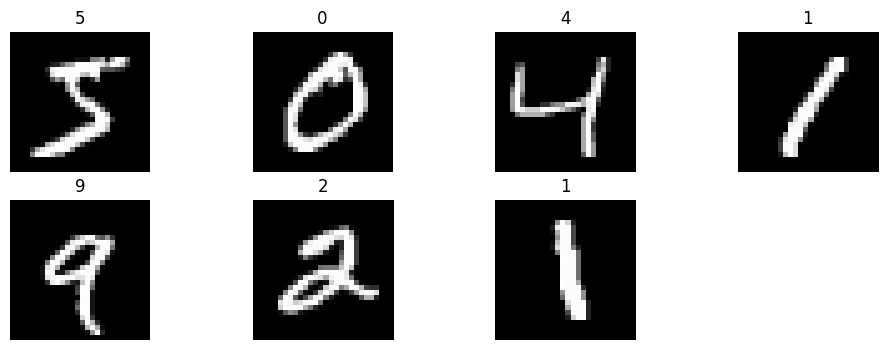

In [91]:
# Displaying first 7 images

plt.figure(figsize=(12, 4))
for i in range(7):
    plt.subplot(2, 4, i + 1)
    plt.imshow(train_img[i], cmap='gray')
    plt.title(train_label[i])
    plt.axis('off')
plt.show()

In [92]:
# Checking the shape of the dataset

print("Training images shape:", train_img.shape)
print("Training labels shape:", train_label.shape)
print("Testing images shape:", test_img.shape)
print("Testing labels shape:", test_label.shape)
print("Image size:", train_img[11].shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)
Image size: (28, 28)


In [93]:
# Checking the data types

print("Training images:", train_img.dtype)
print("Training labels:", train_label.dtype)
print("Testing images:", test_img.dtype)
print("Testing labels:", test_label.dtype)

Training images: uint8
Training labels: uint8
Testing images: uint8
Testing labels: uint8


In [94]:
# Checking pixel value range

print("Minimum pixel value:", train_img.min())
print("Maximum pixel value:", train_img.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [95]:
# Normalizing the image data

train_img = train_img / 255.0
test_img = test_img / 255.0

print("Minimum pixel value:", train_img.min())
print("Maximum pixel value:", train_img.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


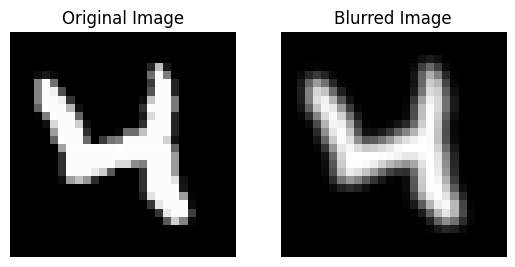

In [104]:
# Applying Gaussian blur

img = train_img[20]
blur_img = cv2.GaussianBlur(img, (3, 3), 0)

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(blur_img, cmap='gray')
plt.title("Blurred Image")
plt.axis('off')
plt.show()

In [97]:
# Reshaping an image

img = train_img[77]
new_img = img.reshape(1, -1)

print("Original shape:", img.shape)
print("New shape:", new_img.shape)

Original shape: (28, 28)
New shape: (1, 784)


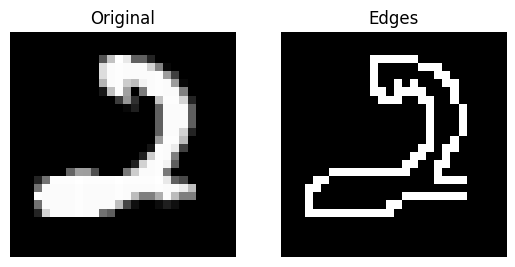

In [98]:
# Detecting image edges

img = (train_img[1010] * 255).astype('uint8')
edge_img = cv2.Canny(img, 30, 100)
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(edge_img, cmap='gray')
plt.title("Edges")
plt.axis('off')
plt.show()

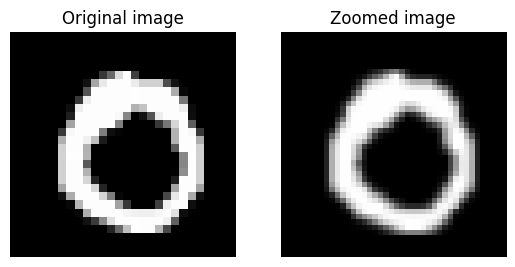

In [99]:
# Zooming an image

img = train_img[56]
zoom_img = cv2.resize(img, None, fx=1.5, fy=1.5)

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original image")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(zoom_img, cmap='gray')
plt.title("Zoomed image")
plt.axis('off')
plt.show()

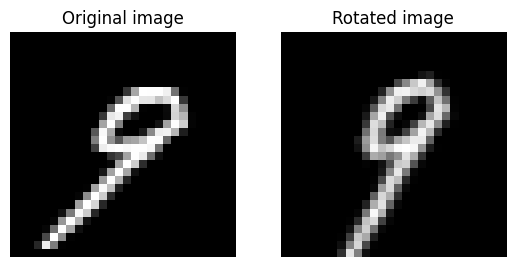

In [100]:
# Rotating an image

img = train_img[501]
matrix = cv2.getRotationMatrix2D((14, 14), 15, 1)
rotate_img = cv2.warpAffine(img, matrix, (28, 28))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original image")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(rotate_img, cmap='gray')
plt.title("Rotated image")
plt.axis('off')
plt.show()

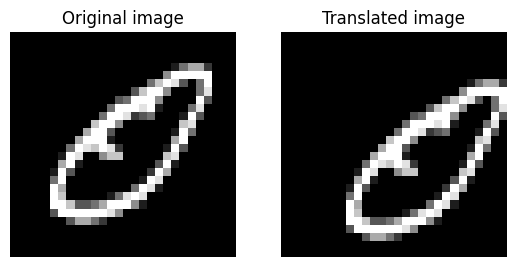

In [101]:
# Translate an image

img = train_img[1015]
matrix = np.float32([[1, 0, 3], [0, 1, 2]])
move_img = cv2.warpAffine(img, matrix, (28, 28))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original image")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(move_img, cmap='gray')
plt.title("Translated image")
plt.axis('off')
plt.show()